1. Librerias

In [9]:
%pip install -q scikit-fuzzy==0.5.0 numpy pandas matplotlib


2. Importaciones

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from pathlib import Path

CARPETA = Path('resultados_AF9')
CARPETA.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})



3. Funciones de pertenencia y reglas

In [11]:
# Iluminacion relativa: 0 = oscuridad, 100 = maxima de la escala elegida.
LUZ = np.linspace(0, 100, 101)
ANGULO = np.linspace(-5, 5, 401)
ENTRADAS = ['Baja', 'Media', 'Alta']
SALIDAS = ['Izquierda fuerte', 'Izquierda suave', 'Sin correccion',
           'Derecha suave', 'Derecha fuerte']

# Los mismos conjuntos se utilizan para ambas LDR.
MF_LUZ = np.array([fuzz.trimf(LUZ, puntos) for puntos in
                   ([0, 0, 50], [0, 50, 100], [50, 100, 100])])
MF_SALIDA = np.array([fuzz.trimf(ANGULO, puntos) for puntos in
    ([-5, -5, -2.5], [-5, -2.5, 0], [-1, 0, 1],
     [0, 2.5, 5], [2.5, 5, 5])])

# Filas = luz izquierda; columnas = luz derecha; orden Baja, Media, Alta.
# Cada numero identifica uno de los cinco conjuntos de salida.
REGLAS = np.array([[2, 3, 4],
                   [1, 2, 3],
                   [0, 1, 2]])
tabla_reglas = pd.DataFrame(
    [[SALIDAS[k] for k in fila] for fila in REGLAS],
    index=['Izq. ' + n for n in ENTRADAS],
    columns=['Der. ' + n for n in ENTRADAS])
print('NUEVE REGLAS MAMDANI TIPO 1\n')
print(tabla_reglas.to_string())
tabla_reglas.to_csv(CARPETA / 'reglas.csv', encoding='utf-8-sig')




NUEVE REGLAS MAMDANI TIPO 1

                   Der. Baja       Der. Media       Der. Alta
Izq. Baja     Sin correccion    Derecha suave  Derecha fuerte
Izq. Media   Izquierda suave   Sin correccion   Derecha suave
Izq. Alta   Izquierda fuerte  Izquierda suave  Sin correccion


4. Inferencia Mamdani

In [12]:
def controlador(izquierda, derecha, detalles=False):
    """Devuelve correccion en grados por actualizacion, no posicion absoluta.

    AND = minimo; implicacion = recorte por minimo; agregacion = maximo;
    desfuzzificacion = centroide de la salida agregada discretizada.
    """
    valores = np.asarray([izquierda, derecha], dtype=float)
    if not np.all(np.isfinite(valores)) or np.any((valores < 0) | (valores > 100)):
        raise ValueError('Ambas iluminaciones deben estar entre 0 y 100.')
    grados_i = np.array([fuzz.interp_membership(LUZ, mf, izquierda) for mf in MF_LUZ])
    grados_d = np.array([fuzz.interp_membership(LUZ, mf, derecha) for mf in MF_LUZ])
    activacion = np.minimum(grados_i[:, None], grados_d[None, :])
    agregada = np.zeros_like(ANGULO)
    for i in range(3):
        for j in range(3):
            recortada = np.minimum(activacion[i, j], MF_SALIDA[REGLAS[i, j]])
            agregada = np.maximum(agregada, recortada)
    if not np.any(agregada > 0):
        raise RuntimeError('No hay reglas activas: revisar cobertura de conjuntos.')
    correccion = float(fuzz.defuzz(ANGULO, agregada, 'centroid'))
    if abs(correccion) < 1e-10:
        correccion = 0.0  # Limpieza de redondeo, no banda muerta del controlador.
    if detalles:
        return correccion, agregada, activacion
    return correccion



5. Grafica de las funciones de pertenencia

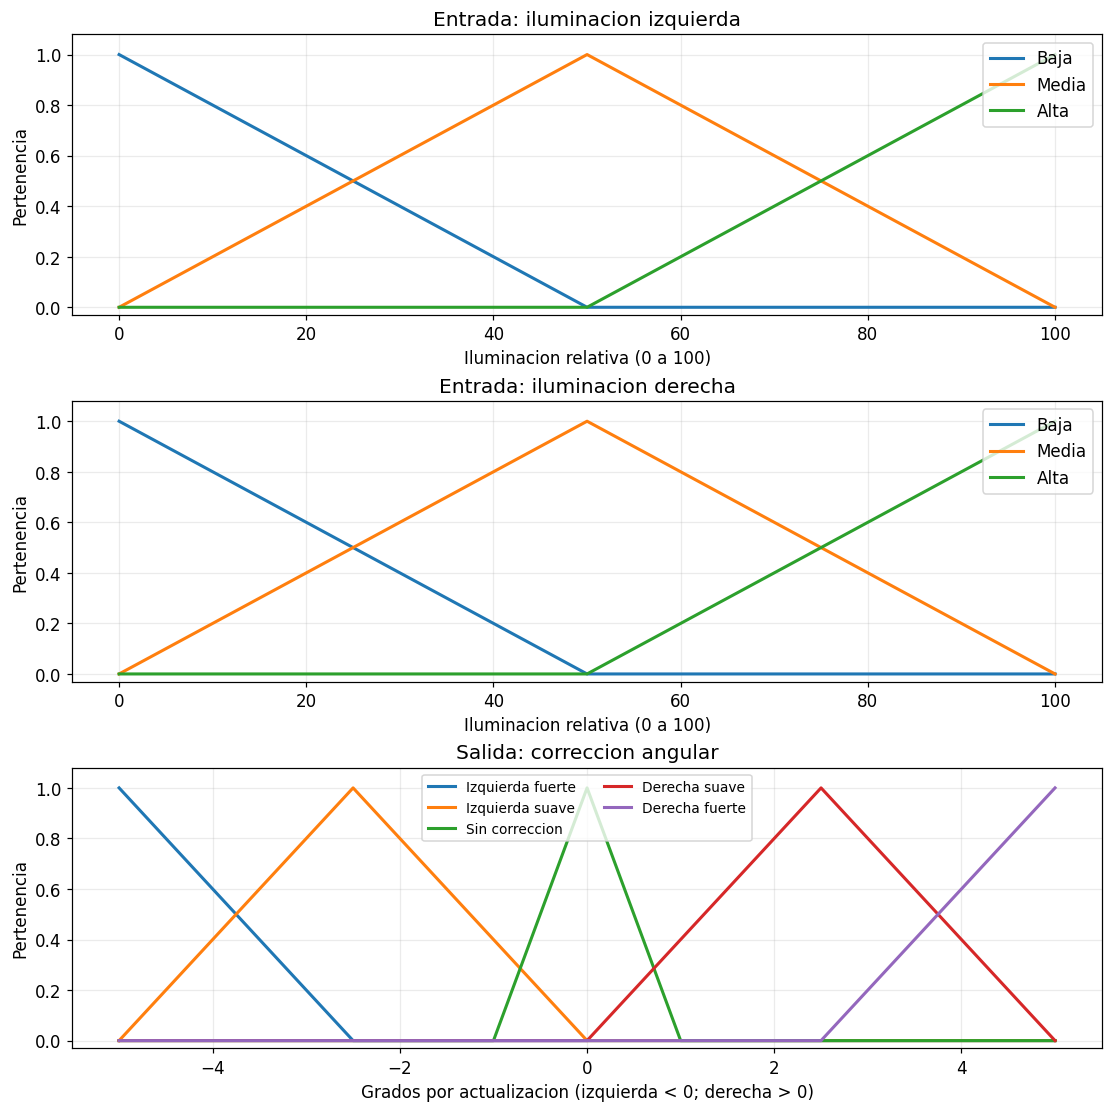

In [13]:
fig, ejes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
for ax, lado in zip(ejes[:2], ['izquierda', 'derecha']):
    for nombre, mf in zip(ENTRADAS, MF_LUZ):
        ax.plot(LUZ, mf, label=nombre, linewidth=2)
    ax.set(title='Entrada: iluminacion ' + lado, xlabel='Iluminacion relativa (0 a 100)',
           ylabel='Pertenencia', ylim=(-0.03, 1.08))
    ax.legend(loc='upper right')
    ax.grid(alpha=0.25)
for nombre, mf in zip(SALIDAS, MF_SALIDA):
    ejes[2].plot(ANGULO, mf, label=nombre, linewidth=2)
ejes[2].set(title='Salida: correccion angular', xlabel='Grados por actualizacion (izquierda < 0; derecha > 0)',
            ylabel='Pertenencia', ylim=(-0.03, 1.08))
ejes[2].legend(loc='upper center', ncol=2, fontsize=9)
ejes[2].grid(alpha=0.25)
fig.savefig(CARPETA / '01_pertenencias.png', dpi=200)
plt.show()



6. Casos de prueba de entrada-salida


CASOS SIMULADOS

 Luz izquierda  Luz derecha  Correccion (grados)        Sentido
             0            0               0.0000 Sin correccion
            50           50               0.0000 Sin correccion
           100          100               0.0000 Sin correccion
           100            0              -4.1667      Izquierda
             0          100               4.1667        Derecha
            70           30              -1.9428      Izquierda
            30           70               1.9428        Derecha
            55           50              -0.8270      Izquierda
            50           55               0.8270        Derecha


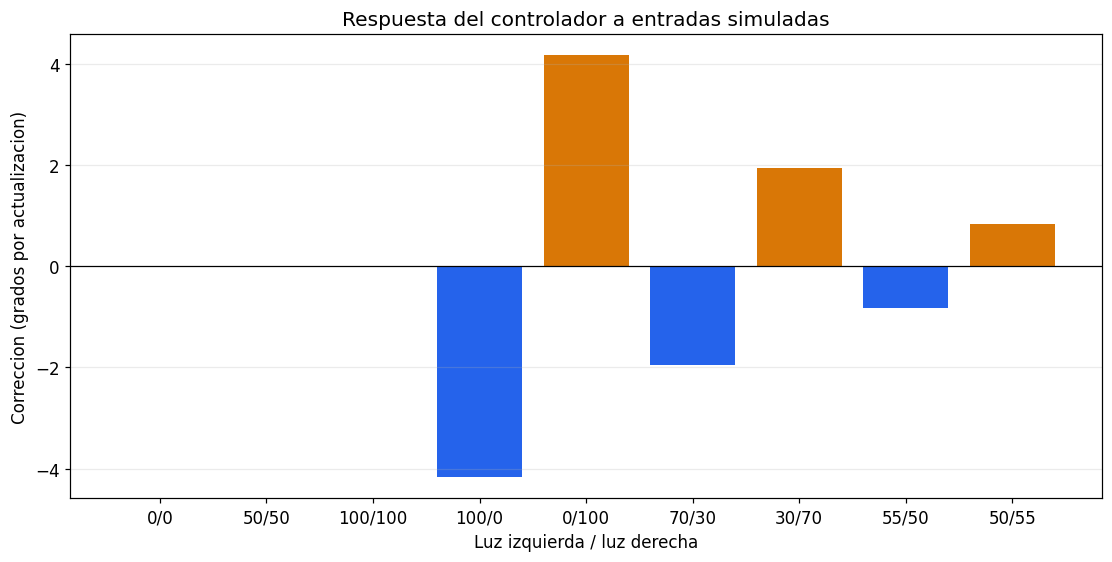

In [14]:
casos = [(0, 0), (50, 50), (100, 100), (100, 0), (0, 100),
         (70, 30), (30, 70), (55, 50), (50, 55)]
resultados = []
for izquierda, derecha in casos:
    delta = controlador(izquierda, derecha)
    sentido = 'Izquierda' if delta < 0 else ('Derecha' if delta > 0 else 'Sin correccion')
    resultados.append([izquierda, derecha, delta, sentido])
tabla = pd.DataFrame(resultados, columns=['Luz izquierda', 'Luz derecha',
                                        'Correccion (grados)', 'Sentido'])
print('\nCASOS SIMULADOS\n')
print(tabla.to_string(index=False, float_format=lambda n: f'{n:.4f}'))
tabla.to_csv(CARPETA / 'casos_simulados.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.bar([f'{i}/{d}' for i, d in casos], tabla['Correccion (grados)'],
       color=['#2563eb' if v < 0 else '#d97706' for v in tabla['Correccion (grados)']])
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Respuesta del controlador a entradas simuladas',
       xlabel='Luz izquierda / luz derecha', ylabel='Correccion (grados por actualizacion)')
ax.grid(axis='y', alpha=0.25)
fig.savefig(CARPETA / '02_casos.png', dpi=200)
plt.show()



7. Superficie de control y verificaciones


Verificaciones aprobadas en 961 combinaciones:
Cobertura, limites, equilibrio, simetria y sentido de giro.


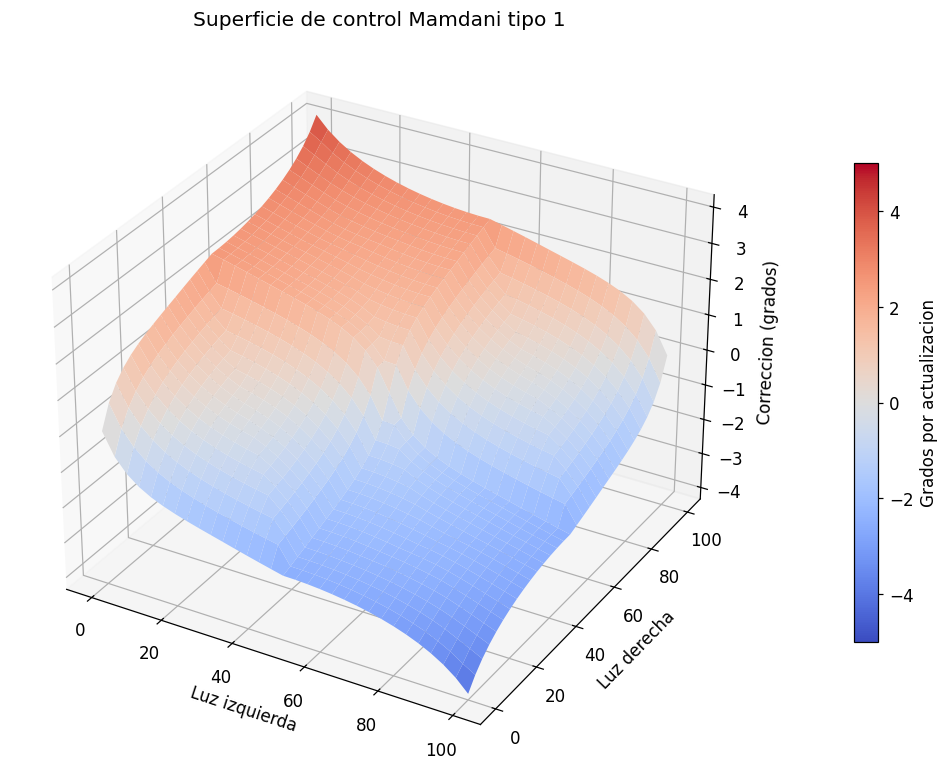

In [15]:
malla = np.linspace(0, 100, 31)
I, D = np.meshgrid(malla, malla)
Z = np.array([[controlador(i, d) for i in malla] for d in malla])
# Verificaciones de cobertura, limites, equilibrio, simetria y sentido de giro.
assert np.isfinite(Z).all() and np.max(np.abs(Z)) <= 5 + 1e-8
assert np.allclose(np.diag(Z), 0, atol=1e-8)
assert np.allclose(Z, -Z.T, atol=1e-8)
assert np.all(Z[I > D] < 0) and np.all(Z[D > I] > 0)
print('\nVerificaciones aprobadas en 961 combinaciones:')
print('Cobertura, limites, equilibrio, simetria y sentido de giro.')
fig = plt.figure(figsize=(10, 7), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
superficie = ax.plot_surface(I, D, Z, cmap='coolwarm', vmin=-5, vmax=5)
ax.set(xlabel='Luz izquierda', ylabel='Luz derecha', zlabel='Correccion (grados)',
       title='Superficie de control Mamdani tipo 1')
fig.colorbar(superficie, ax=ax, shrink=0.65, pad=0.12, label='Grados por actualizacion')
fig.savefig(CARPETA / '03_superficie.png', dpi=200)
plt.show()



8. Prueba manual


Izquierda: 80; derecha: 20
Correccion difusa: -2.3333 grados por actualizacion
Posicion ordenada de ejemplo: 90.00 -> 87.67 grados
Conjuntos de salida negativos = izquierda; positivos = derecha.
Activacion de las 9 reglas (filas izquierda, columnas derecha):
       Baja  Media  Alta
Baja    0.0    0.0   0.0
Media   0.4    0.4   0.0
Alta    0.6    0.4   0.0


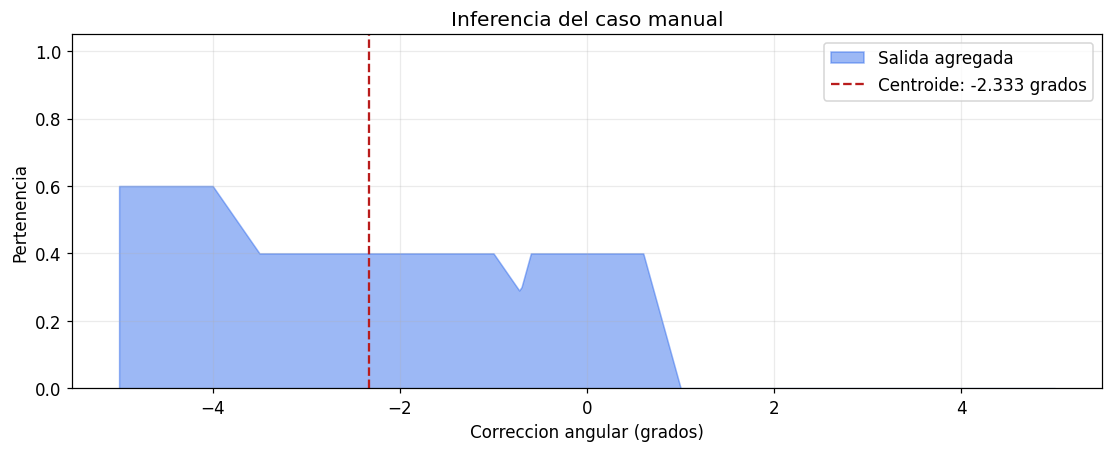


Figuras y tablas guardadas en: /content/resultados_AF9
Esta simulacion valida el controlador; no modela la dinamica optica/mecanica ni usa mediciones reales.


In [16]:
LUZ_IZQUIERDA = 80
LUZ_DERECHA = 20
POSICION_ACTUAL = 90  # Ejemplo de posicion ordenada, no medicion de un servo real.

delta, agregada, activacion = controlador(LUZ_IZQUIERDA, LUZ_DERECHA, detalles=True)
# Limites ilustrativos para la futura maqueta; se ajustaran al montaje real.
nueva_posicion = np.clip(POSICION_ACTUAL + delta, 15, 165)
print(f'\nIzquierda: {LUZ_IZQUIERDA}; derecha: {LUZ_DERECHA}')
print(f'Correccion difusa: {delta:.4f} grados por actualizacion')
print(f'Posicion ordenada de ejemplo: {POSICION_ACTUAL:.2f} -> {nueva_posicion:.2f} grados')
print('Conjuntos de salida negativos = izquierda; positivos = derecha.')
print('Activacion de las 9 reglas (filas izquierda, columnas derecha):')
print(pd.DataFrame(activacion, index=ENTRADAS, columns=ENTRADAS).round(3))
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.fill_between(ANGULO, agregada, alpha=0.45, color='#2563eb', label='Salida agregada')
ax.axvline(delta, color='#b91c1c', linestyle='--', label=f'Centroide: {delta:.3f} grados')
ax.set(title='Inferencia del caso manual', xlabel='Correccion angular (grados)',
       ylabel='Pertenencia', ylim=(0, 1.05))
ax.legend()
ax.grid(alpha=0.25)
fig.savefig(CARPETA / '04_inferencia_manual.png', dpi=200)
plt.show()
print('\nFiguras y tablas guardadas en:', CARPETA.resolve())
print('Esta simulacion valida el controlador; no modela la dinamica optica/mecanica ni usa mediciones reales.')


In [17]:
import shutil
archivo_zip = shutil.make_archive('AF9_Resultados_Simulacion', 'zip', str(CARPETA))
try:
    from google.colab import files
except ImportError:
    print('ZIP disponible en:', archivo_zip)
else:
    files.download(archivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>